# Entrega 3: regresión

**TP Integrador de Aprendizaje Automático**

Proyecto: rendimiento de cultivos por partido en la Provincia de Buenos Aires.

Objetivo: predecir el **ratio** entre el rendimiento de la campaña y el promedio de las cinco campañas anteriores. La predicción se convierte a kg/ha multiplicando por ese promedio.

Protocolo:

1. Se entrena cada configuración con **train** (1981/82 a 2013/14) y se mide en **validación** (2014/15 a 2018/19).
2. Se elige la mejor configuración de cada familia por el **MAE del ratio en validación**. El test no interviene.
3. Las configuraciones elegidas se reentrenan con **train + validación** y se evalúan **una sola vez en test** (2019/20 a 2024/25).

Modelos comparados:

- Dummy por cultivo (baseline obligatorio).
- Promedio de 5 campañas, `ratio = 1` (baseline del problema).
- `DecisionTreeRegressor`, con distintas profundidades y tamaños mínimos de hoja.
- `KNeighborsRegressor`, con `StandardScaler` dentro del Pipeline y distintos valores de k.

Cada familia se prueba con y sin variables climáticas.

In [1]:
from pathlib import Path
import sys

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.inspection import permutation_importance

ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

from src.config import CROPS, FIGURAS_DIR, RANDOM_STATE, REGRESOR_FILE, REGRESOR_METADATA, THRESHOLD
from src.baselines import regression_metrics
from src.regresion import (
    CLIMA_COLS,
    FEATURE_SETS,
    feature_columns,
    load_data,
    make_knn,
    make_tree,
    run,
    split_data,
)

# src.baselines fija el backend Agg para correr por consola; en el notebook se
# vuelve al backend inline para que las figuras se vean.
%matplotlib inline

COLOR_SPLIT = {"train": "#2a78d6", "validacion": "#eb6834", "test": "#1baf7a"}
COLOR_MODELO = {
    "Dummy por cultivo": "#b5b4ae",
    "Promedio 5 campañas": "#6b6a65",
    "KNeighborsRegressor": "#2a78d6",
    "DecisionTreeRegressor": "#eb6834",
}
TINTA_SECUNDARIA = "#52514e"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Datos y variables

Se usa `dataset_modelado_con_clima.csv`, generado en la Entrega 2.

**Predictores**, todos disponibles en la fecha de corte:

- `cultivo`, con one-hot;
- `superficie_sembrada`, en logaritmo por su cola derecha larga;
- `prev5` y `prev5_ceros`;
- las nueve variables climáticas de la ventana, solo en el conjunto `con_clima`.

**Excluidos:**

- `campania_inicio`: el ratio ya no tiene tendencia, y en test el año queda fuera del rango visto en entrenamiento. Un árbol trataría a todos los años nuevos como el último que vio y KNN mediría distancias contra años que nunca aparecieron.
- `municipio_id`: el nivel productivo de cada partido ya está en `prev5`. Como one-hot agregaría más de 100 columnas que distorsionan las distancias de KNN.
- `produccion`, `superficie_cosechada`, `rendimiento`, `ratio` y las clases: son el objetivo o se conocen después de la cosecha.

In [2]:
df = load_data()
train, val, test = split_data(df)
print(f"Train: {len(train):,} | Validación: {len(val):,} | Test: {len(test):,}")
for nombre in FEATURE_SETS:
    print(f"{nombre}: {feature_columns(nombre)}")

Train: 11,147 | Validación: 1,828 | Test: 2,204
sin_clima: ['cultivo', 'superficie_sembrada', 'prev5', 'prev5_ceros']
con_clima: ['cultivo', 'superficie_sembrada', 'prev5', 'prev5_ceros', 'clima_precip_total_mm', 'clima_dias_tmax_30', 'clima_tmax_media_c', 'clima_tmin_media_c', 'clima_humedad_media_pct', 'clima_sequia_max_dias', 'clima_precip_pre_siembra_mm', 'clima_dias_helada', 'clima_dias_lluvia']


## 2. Búsqueda de hiperparámetros con validación

`run()` ejecuta todo el protocolo: la búsqueda, la selección, el reentrenamiento, la evaluación en test y el guardado del regresor. Se prueban:

- **Árbol:** `max_depth` en 2, 3, 4, 5, 6, 8, 10, 12, 15 y sin límite; `min_samples_leaf` en 1, 10, 50 y 100.
- **KNN:** k entre 1 y 800; pesos `uniform` y `distance`.

En total son 136 configuraciones. La semilla del árbol es 42.

In [3]:
res = run(verbose=False)
busqueda = res["busqueda"]
elegidos = res["elegidos"]
print("Configuraciones evaluadas:", len(busqueda))
display(elegidos[["modelo", "variables", "params", "mae_ratio_train", "mae_ratio_val", "rmse_ratio_val", "r2_ratio_val"]].round(4))

mae_val_base = {
    "Dummy por cultivo": res["comparacion"].set_index("modelo").loc["Dummy por cultivo", "mae_ratio_val"],
    "Promedio 5 campañas": res["comparacion"].set_index("modelo").loc["Promedio 5 campañas", "mae_ratio_val"],
}
print("MAE de validación de los baselines:", {k: round(v, 4) for k, v in mae_val_base.items()})

Configuraciones evaluadas: 136


,modelo,variables,params,mae_ratio_train,mae_ratio_val,rmse_ratio_val,r2_ratio_val
0,KNeighborsRegressor,con_clima,"n_neighbors=300, weights=distance",0.0000,0.1599,0.3020,0.0874
1,DecisionTreeRegressor,sin_clima,"max_depth=4, min_samples_leaf=1",0.2015,0.1617,0.2843,0.1914
2,DecisionTreeRegressor,con_clima,"max_depth=4, min_samples_leaf=1",0.1937,0.1625,0.2628,0.3092
3,KNeighborsRegressor,sin_clima,"n_neighbors=800, weights=uniform",0.2055,0.1637,0.3113,0.0307


MAE de validación de los baselines: {'Dummy por cultivo': np.float64(0.1645), 'Promedio 5 campañas': np.float64(0.1758)}


Las cuatro mejores configuraciones superan a los dos baselines en validación. La mejor es **KNN con clima, k = 300 y pesos por distancia**, con un MAE de 0,1599 contra 0,1645 del Dummy y 0,1758 del promedio de 5 campañas.

Con pesos por distancia, el MAE de train de KNN es casi 0. Cada punto de train es su propio vecino a distancia cero y recibe todo el peso. No indica sobreajuste: el desempeño real se lee en validación.

### 2.1 Árbol: profundidad

min_samples_leaf,1.0,10.0,50.0,100.0
max_depth,,,,
2.0,0.1639,0.1661,0.1658,0.1680
3.0,0.1647,0.1667,0.1664,0.1683
4.0,0.1625,0.1646,0.1647,0.1684
5.0,0.1642,0.1668,0.1673,0.1693
6.0,0.1657,0.1669,0.1639,0.1736
8.0,0.1696,0.1720,0.1715,0.1704
10.0,0.1740,0.1698,0.1710,0.1747
12.0,0.1735,0.1768,0.1812,0.1780
15.0,0.1973,0.1841,0.1845,0.1796


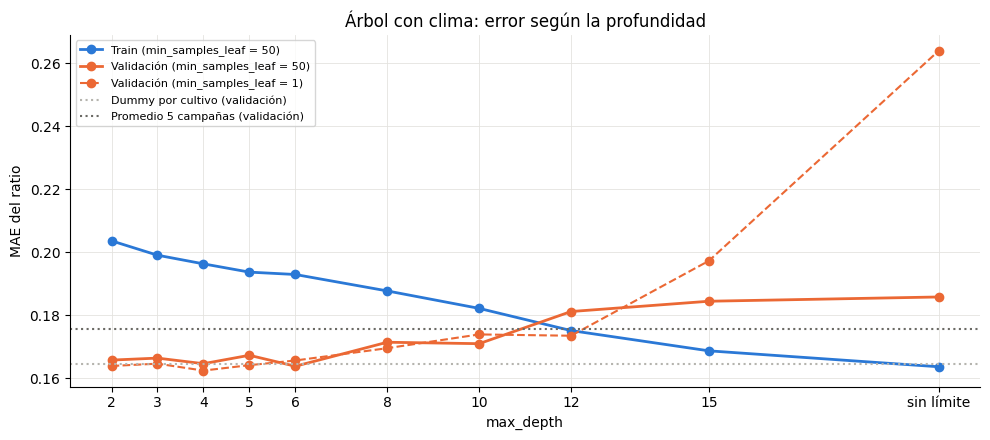

In [4]:
arbol = busqueda[(busqueda["familia"] == "arbol") & (busqueda["variables"] == "con_clima")].copy()
arbol["prof"] = arbol["max_depth"].fillna(20)
display(arbol.pivot_table(index="max_depth", columns="min_samples_leaf", values="mae_ratio_val", dropna=False).round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
hoja = arbol[arbol["min_samples_leaf"] == 50].sort_values("prof")
ax.plot(hoja["prof"], hoja["mae_ratio_train"], marker="o", color=COLOR_SPLIT["train"], linewidth=2, label="Train (min_samples_leaf = 50)")
ax.plot(hoja["prof"], hoja["mae_ratio_val"], marker="o", color=COLOR_SPLIT["validacion"], linewidth=2, label="Validación (min_samples_leaf = 50)")
hoja1 = arbol[arbol["min_samples_leaf"] == 1].sort_values("prof")
ax.plot(hoja1["prof"], hoja1["mae_ratio_val"], marker="o", color=COLOR_SPLIT["validacion"], linewidth=1.5, linestyle="--", label="Validación (min_samples_leaf = 1)")
for nombre, valor in mae_val_base.items():
    ax.axhline(valor, color=COLOR_MODELO[nombre], linewidth=1.5, linestyle=":", label=f"{nombre} (validación)")
ax.set_xticks(hoja["prof"], [str(int(p)) if p < 20 else "sin límite" for p in hoja["prof"]])
ax.set_xlabel("max_depth")
ax.set_ylabel("MAE del ratio")
ax.set_title("Árbol con clima: error según la profundidad")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "arbol_profundidad.png", dpi=150)
plt.show()

El error de train baja siempre al aumentar la profundidad. El de validación baja hasta profundidad 4 y después sube: a partir de 8 el árbol memoriza campañas de train que no se repiten. Sin límite de profundidad y con hojas de 1 fila, el MAE de validación llega a 0,26, peor que cualquier baseline.

El mínimo tamaño de hoja funciona como regularización: con `min_samples_leaf = 50`, los árboles profundos se degradan mucho menos.

### 2.2 KNN: cantidad de vecinos

weights,distance,uniform
n_neighbors,,
1.0,0.2252,0.2252
3.0,0.1994,0.1989
5.0,0.1934,0.1935
10.0,0.1860,0.1858
15.0,0.1798,0.1794
25.0,0.1740,0.1734
50.0,0.1683,0.1685
75.0,0.1651,0.1652
100.0,0.1631,0.1634


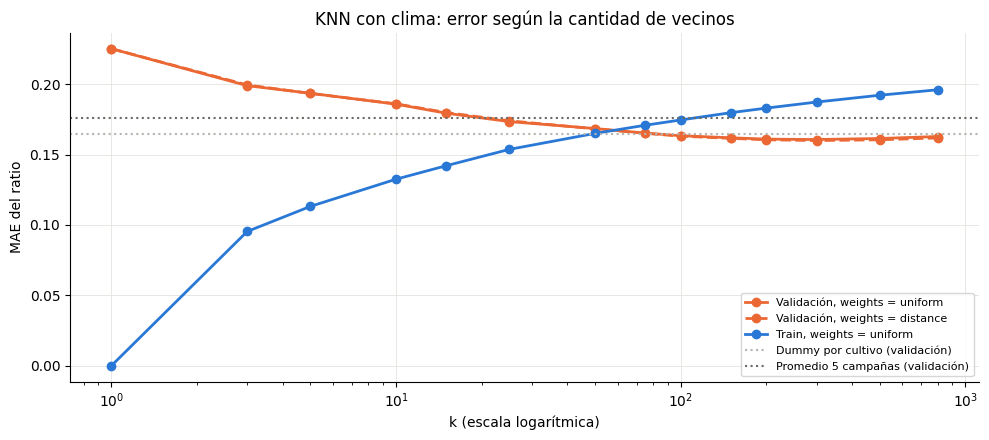

In [5]:
knn = busqueda[(busqueda["familia"] == "knn") & (busqueda["variables"] == "con_clima")]
display(knn.pivot(index="n_neighbors", columns="weights", values="mae_ratio_val").round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
for weights, estilo in [("uniform", "-"), ("distance", "--")]:
    sub = knn[knn["weights"] == weights].sort_values("n_neighbors")
    ax.plot(sub["n_neighbors"], sub["mae_ratio_val"], marker="o", linestyle=estilo, linewidth=2,
            color=COLOR_SPLIT["validacion"], label=f"Validación, weights = {weights}")
sub = knn[knn["weights"] == "uniform"].sort_values("n_neighbors")
ax.plot(sub["n_neighbors"], sub["mae_ratio_train"], marker="o", linewidth=2, color=COLOR_SPLIT["train"], label="Train, weights = uniform")
for nombre, valor in mae_val_base.items():
    ax.axhline(valor, color=COLOR_MODELO[nombre], linewidth=1.5, linestyle=":", label=f"{nombre} (validación)")
ax.set_xscale("log")
ax.set_xlabel("k (escala logarítmica)")
ax.set_ylabel("MAE del ratio")
ax.set_title("KNN con clima: error según la cantidad de vecinos")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "knn_k.png", dpi=150)
plt.show()

Con k = 1 el modelo copia al vecino más parecido: el MAE de train es 0 y el de validación, 0,225. Al aumentar k, la predicción promedia más casos y el error de validación baja hasta k = 300. Con k = 500 y k = 800 vuelve a subir: el modelo promedia casos demasiado distintos.

Que el mejor k sea tan grande es una señal: la relación entre clima y ratio es ruidosa, y el modelo necesita promediar muchos casos para encontrarla. Los pesos por distancia mejoran apenas a los uniformes.

### 2.3 Con y sin clima

In [6]:
display(
    elegidos.pivot(index="modelo", columns="variables", values="mae_ratio_val").round(4)
)

variables,con_clima,sin_clima
modelo,,
DecisionTreeRegressor,0.1625,0.1617
KNeighborsRegressor,0.1599,0.1637


El clima mejora a KNN (0,1637 → 0,1599) y empeora levemente al árbol (0,1617 → 0,1625). En validación, el aporte del clima es chico. La sección 4 muestra por qué: la señal está concentrada en maíz y soja.

### 2.4 Alternativas evaluadas y descartadas

Hubo dos mejoras con motivación previa. Se evaluaron **solo con validación**:

1. **Anomalías climáticas.** El ratio es relativo a la historia del partido, pero el clima está en valores absolutos: 400 mm pueden ser normales en el oeste y una sequía en el este. Se calculó cada variable climática como diferencia contra la media del mismo partido y cultivo. La media se ajusta solo con los datos de entrenamiento.
2. **Ventana de entrenamiento.** El ratio medio baja con el tiempo, de 1,15 en los ochenta a 1,05 en 2015-2019. Se probó entrenar desde 1990 y desde 2000.

Primera ejecución: los resultados de test de la versión con clima absoluto se vieron antes de probar estas alternativas. Por eso la decisión se toma exclusivamente con validación, y se mantiene la regla de no elegir por test.

In [7]:
claves = ["municipio_id", "cultivo"]
ANOM = [c.replace("clima_", "anom_") for c in CLIMA_COLS]


def agregar_anomalias(ajuste: pd.DataFrame, datos: pd.DataFrame) -> pd.DataFrame:
    # Media por partido y cultivo ajustada solo con `ajuste`; si falta, media del cultivo.
    por_partido = ajuste.groupby(claves)[CLIMA_COLS].mean().reset_index()
    por_cultivo = ajuste.groupby("cultivo")[CLIMA_COLS].mean().reset_index()
    ref = datos[claves].merge(por_partido, on=claves, how="left")[CLIMA_COLS]
    ref = ref.fillna(datos[["cultivo"]].merge(por_cultivo, on="cultivo", how="left")[CLIMA_COLS])
    out = datos.copy()
    out[ANOM] = datos[CLIMA_COLS].to_numpy() - ref.to_numpy()
    return out


FEATURE_SETS["anomalias"] = FEATURE_SETS["sin_clima"] + ANOM
filas = []
for inicio in [1981, 1990, 2000]:
    tr = train[train["campania_inicio"] >= inicio]
    tr_a, va_a = agregar_anomalias(tr, tr), agregar_anomalias(tr, val)
    for variables in ["con_clima", "anomalias"]:
        cols = feature_columns(variables)
        for k in [100, 200, 300, 500]:
            pred = make_knn(variables, k, "distance").fit(tr_a[cols], tr_a["ratio"]).predict(va_a[cols])
            filas.append(("KNN", inicio, variables, f"k={k}", regression_metrics(val["ratio"], pred, val["prev5"])["mae_ratio"]))
        for depth in [3, 4, 5, 6]:
            for leaf in [50, 100]:
                pred = make_tree(variables, depth, leaf).fit(tr_a[cols], tr_a["ratio"]).predict(va_a[cols])
                filas.append(("Árbol", inicio, variables, f"depth={depth}, leaf={leaf}", regression_metrics(val["ratio"], pred, val["prev5"])["mae_ratio"]))
del FEATURE_SETS["anomalias"]

alternativas = pd.DataFrame(filas, columns=["modelo", "entrena desde", "clima", "mejor config", "mae_ratio_val"])
mejores = alternativas.loc[alternativas.groupby(["modelo", "entrena desde", "clima"])["mae_ratio_val"].idxmin()]
display(mejores.sort_values("mae_ratio_val").round(4).reset_index(drop=True))

,modelo,entrena desde,clima,mejor config,mae_ratio_val
0,KNN,1981,con_clima,k=300,0.1599
1,KNN,1990,con_clima,k=200,0.1601
2,KNN,1981,anomalias,k=300,0.1623
3,Árbol,1990,anomalias,"depth=5, leaf=50",0.1628
4,KNN,2000,con_clima,k=300,0.1637
5,KNN,1990,anomalias,k=200,0.1639
6,Árbol,1981,con_clima,"depth=6, leaf=50",0.1639
7,Árbol,2000,con_clima,"depth=3, leaf=50",0.1643
8,Árbol,1990,con_clima,"depth=3, leaf=50",0.1650
9,KNN,2000,anomalias,k=300,0.1664


Ninguna alternativa mejora a la configuración original, KNN con clima absoluto entrenado desde 1981 (0,1599). Las anomalías empeoran a KNN en las tres ventanas. Las anomalías no mejoran al árbol: 0,1628 contra 0,1625 de la configuración original, y quedan lejos del KNN. Entrenar desde 2000 empeora a los dos modelos. Se descartan las dos alternativas.

## 3. Comparación final: validación y test

Las configuraciones elegidas se reentrenan con train + validación y se evalúan en test. Los baselines también usan train + validación: el Dummy recalcula la media del ratio por cultivo con esos datos.

In [8]:
comparacion = res["comparacion"]
cols_tabla = ["modelo", "params", "mae_ratio_val", "mae_ratio_test", "rmse_ratio_test", "r2_ratio_test",
              "mae_kg_test", "rmse_kg_test", "r2_kg_test"]
display(comparacion[cols_tabla].round(4))
print("Regresor seleccionado:", res["seleccionado"])

,modelo,params,mae_ratio_val,mae_ratio_test,rmse_ratio_test,r2_ratio_test,mae_kg_test,rmse_kg_test,r2_kg_test
0,Dummy por cultivo,-,0.1645,0.1765,0.2441,-0.3072,755.6576,1174.0761,0.7038
1,Promedio 5 campañas,-,0.1758,0.1538,0.2172,-0.0353,626.2764,980.5417,0.7934
2,KNeighborsRegressor (con_clima),"n_neighbors=300, weights=distance",0.1599,0.1588,0.2233,-0.0942,636.7792,937.8296,0.8110
3,DecisionTreeRegressor (sin_clima),"max_depth=4, min_samples_leaf=1",0.1617,0.1722,0.2606,-0.4904,713.3738,1122.6683,0.7292
4,DecisionTreeRegressor (con_clima),"max_depth=4, min_samples_leaf=1",0.1625,0.1632,0.2462,-0.3306,657.6831,954.5055,0.8042
5,KNeighborsRegressor (sin_clima),"n_neighbors=800, weights=uniform",0.1637,0.1639,0.2325,-0.1862,675.2678,1059.4110,0.7588


Regresor seleccionado: KNeighborsRegressor (con_clima)


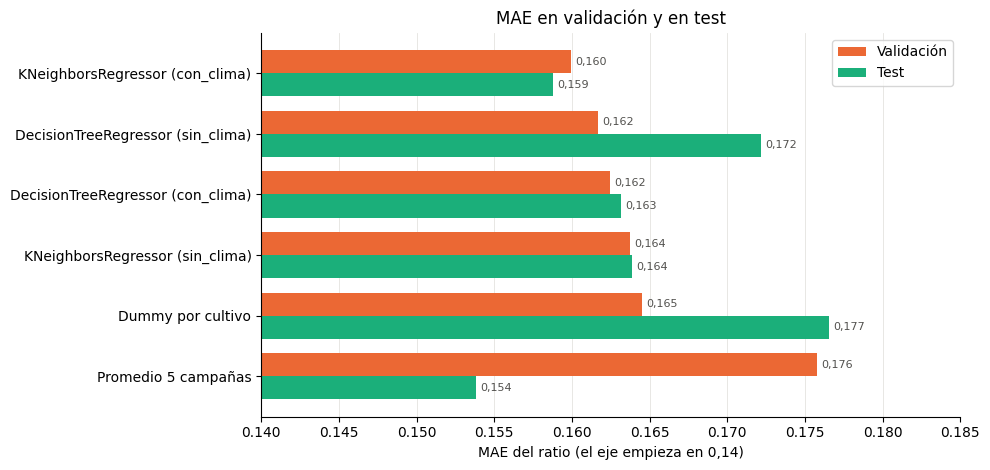

In [9]:
orden = comparacion.sort_values("mae_ratio_val", ascending=False)
y = np.arange(len(orden))
alto = 0.38
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(y + alto / 2, orden["mae_ratio_val"], alto, color=COLOR_SPLIT["validacion"], label="Validación")
ax.barh(y - alto / 2, orden["mae_ratio_test"], alto, color=COLOR_SPLIT["test"], label="Test")
for i, (v, t) in enumerate(zip(orden["mae_ratio_val"], orden["mae_ratio_test"])):
    ax.annotate(f"{v:.3f}".replace(".", ","), (v, i + alto / 2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=TINTA_SECUNDARIA)
    ax.annotate(f"{t:.3f}".replace(".", ","), (t, i - alto / 2), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=TINTA_SECUNDARIA)
ax.set_yticks(y, orden["modelo"])
ax.set_xlim(0.14, 0.185)
ax.set_xlabel("MAE del ratio (el eje empieza en 0,14)")
ax.set_title("MAE en validación y en test")
ax.legend(loc="upper right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "regresion_comparacion_mae.png", dpi=150)
plt.show()

**Lectura:**

- En **validación**, el regresor seleccionado (KNN con clima) supera a los dos baselines.
- En **test**, supera al Dummy (MAE 0,159 contra 0,177) pero **no supera al promedio de 5 campañas en MAE** (0,159 contra 0,154, o 637 contra 626 kg/ha).
- En las métricas cuadráticas el resultado se invierte: el KNN tiene menor RMSE en kg/ha (938 contra 981) y mayor R² en kg/ha (0,811 contra 0,793). Comete menos errores grandes, pero un poco más de errores chicos.
- El R² del ratio es negativo en test para todos los modelos. No significa que no aprendan nada: el test tiene un nivel medio (0,96) que ningún modelo conocía. El R² compara contra la media del test, una referencia que no está disponible al momento de predecir.

La sección 4 explica de dónde viene la diferencia.

## 4. Errores por campaña y por cultivo

modelo,Dummy por cultivo,Promedio 5 campañas,KNeighborsRegressor,ratio real medio,ratio predicho KNN
campania_inicio,,,,,
2019,0.144,0.107,0.143,0.958,1.061
2020,0.154,0.121,0.134,0.965,1.055
2021,0.156,0.122,0.149,0.954,1.081
2022,0.363,0.313,0.270,0.773,0.950
2023,0.146,0.150,0.143,1.043,1.096
2024,0.098,0.110,0.114,1.066,1.046


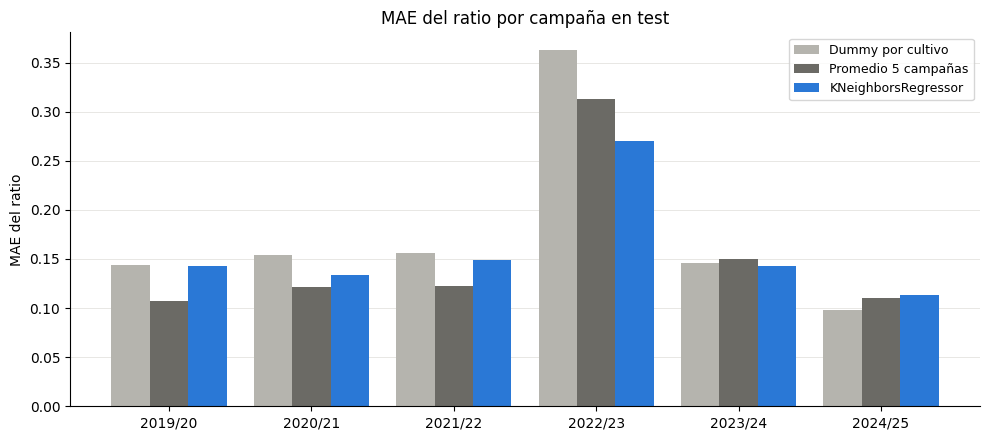

In [10]:
por_campania = res["por_campania"]
etiquetas = {"dummy": "Dummy por cultivo", "prev5": "Promedio 5 campañas", "seleccionado": "KNeighborsRegressor"}
tabla = por_campania.pivot(index="campania_inicio", columns="modelo", values="mae_ratio").rename(columns=etiquetas)
tabla["ratio real medio"] = por_campania.groupby("campania_inicio")["ratio_real_medio"].first()
tabla["ratio predicho KNN"] = por_campania[por_campania["modelo"] == "seleccionado"].set_index("campania_inicio")["ratio_pred_medio"]
display(tabla.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(tabla))
ancho = 0.27
for i, nombre in enumerate(["Dummy por cultivo", "Promedio 5 campañas", "KNeighborsRegressor"]):
    ax.bar(x + (i - 1) * ancho, tabla[nombre], ancho, color=COLOR_MODELO[nombre], label=nombre)
ax.set_xticks(x, [f"{a}/{str(a + 1)[-2:]}" for a in tabla.index])
ax.set_ylabel("MAE del ratio")
ax.set_title("MAE del ratio por campaña en test")
ax.legend(fontsize=9)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "regresion_mae_por_campania.png", dpi=150)
plt.show()

- En **2022/23**, la sequía, el KNN es claramente mejor: MAE de 0,270 contra 0,313 del promedio de 5 campañas. Es el único año del test en que el clima mueve la predicción hacia abajo (ratio predicho medio 0,95).
- En **2019/20 a 2021/22** pierde contra el promedio de 5 campañas. Esos años tuvieron un ratio real cercano a 0,96 y el KNN predijo alrededor de 1,06: arrastra el nivel de entrenamiento, donde el ratio medio era 1,08.
- En **2023/24 y 2024/25**, años buenos, los tres modelos quedan parejos.

El modelo aprendió algo útil del clima, pero tiene un **sesgo de nivel**: en promedio predice 1,048 cuando el test tuvo 0,960.

In [11]:
pred = res["predicciones"]
sesgo = (pred["ratio_pred"] - pred["ratio"]).mean()
print(f"Ratio predicho medio en test: {pred['ratio_pred'].mean():.3f} | real: {pred['ratio'].mean():.3f} | sesgo: {sesgo:+.3f}")
print(f"Correlación entre predicción y valor real (Spearman): {pred['ratio'].corr(pred['ratio_pred'], method='spearman'):.3f}")
print(f"Desvío estándar de la predicción: {pred['ratio_pred'].std():.3f} | del valor real: {pred['ratio'].std():.3f}")
# Diagnóstico, no es un modelo: usa la media del test, que no se conoce al predecir.
print(f"MAE si se quitara el sesgo (diagnóstico): {(pred['ratio_pred'] - sesgo - pred['ratio']).abs().mean():.4f}")

Ratio predicho medio en test: 1.048 | real: 0.960 | sesgo: +0.088
Correlación entre predicción y valor real (Spearman): 0.306
Desvío estándar de la predicción: 0.100 | del valor real: 0.214
MAE si se quitara el sesgo (diagnóstico): 0.1428


Si se le restara el sesgo, el MAE del KNN bajaría a 0,143, mejor que el 0,154 del promedio de 5 campañas. Es solo un diagnóstico: el sesgo se calcula con el test y no se conoce al predecir. Muestra que el modelo **ordena** bien los casos, porque la correlación con el valor real es positiva, y que el problema principal está en el **nivel**.

Es un cambio de distribución entre períodos. El ratio medio bajó de 1,08 en train a 0,96 en test: el crecimiento tecnológico se desaceleró y hubo varios años secos. La validación (2014-2018, ratio medio 1,07) no lo podía anticipar.

In [12]:
por_cultivo = res["por_cultivo"]
display(por_cultivo.pivot(index="cultivo", columns="modelo", values="mae_ratio").rename(columns=etiquetas).round(3))
display(por_cultivo.pivot(index="cultivo", columns="modelo", values="r2_ratio").rename(columns=etiquetas).round(3))

modelo,Dummy por cultivo,Promedio 5 campañas,KNeighborsRegressor
cultivo,,,
Girasol,0.123,0.112,0.128
Maíz,0.196,0.153,0.153
Soja total,0.181,0.162,0.143
Trigo total,0.194,0.179,0.205


modelo,Dummy por cultivo,Promedio 5 campañas,KNeighborsRegressor
cultivo,,,
Girasol,-0.148,-0.019,-0.236
Maíz,-0.495,-0.091,-0.171
Soja total,-0.294,-0.054,0.288
Trigo total,-0.272,-0.042,-0.360


- **Soja:** el KNN es el mejor modelo, con MAE de 0,143 contra 0,162 y el único R² positivo (0,29).
- **Maíz:** empata con el promedio de 5 campañas (0,153).
- **Trigo y girasol:** pierde. Era esperable: en la Entrega 2, las correlaciones del clima con el ratio eran casi nulas en estos dos cultivos.

El clima de la ventana explica el rendimiento de los cultivos de verano, sobre todo la soja. Para trigo y girasol harían falta otras variables.

## 5. Importancia de las variables

Se calcula por permutación sobre **validación**, con el KNN ajustado en train: cuánto empeora el MAE cuando se mezcla al azar cada variable.

,variable,aumento_mae,desvio
4,clima_precip_total_mm,0.0106,0.0008
8,clima_humedad_media_pct,0.0038,0.0005
2,prev5,0.0032,0.0004
3,prev5_ceros,0.0030,0.0001
9,clima_sequia_max_dias,0.0020,0.0002
6,clima_tmax_media_c,0.0015,0.0002
5,clima_dias_tmax_30,0.0013,0.0002
0,cultivo,0.0005,0.0002
11,clima_dias_helada,0.0004,0.0001
10,clima_precip_pre_siembra_mm,0.0002,0.0003


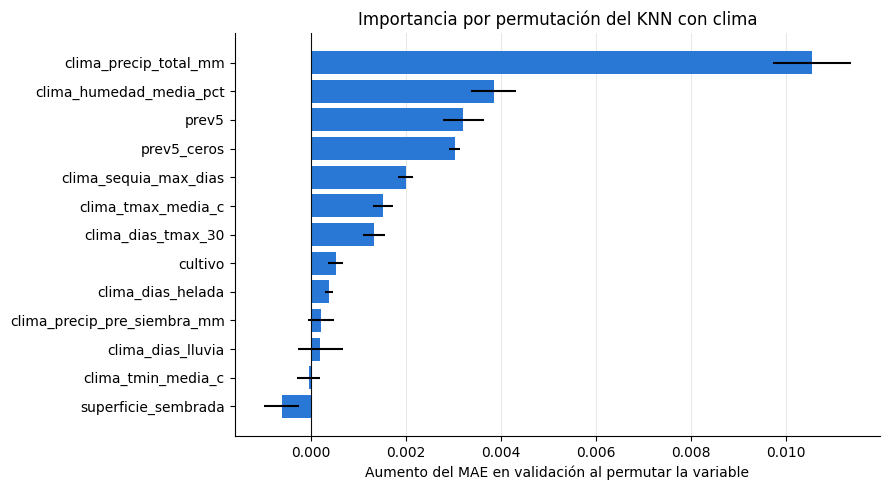

In [13]:
cols_knn = feature_columns("con_clima")
knn_train = make_knn("con_clima", 300, "distance").fit(train[cols_knn], train["ratio"])
imp = permutation_importance(knn_train, val[cols_knn], val["ratio"], scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=RANDOM_STATE)
importancia = pd.DataFrame({"variable": cols_knn, "aumento_mae": imp.importances_mean, "desvio": imp.importances_std})
importancia = importancia.sort_values("aumento_mae")
display(importancia.sort_values("aumento_mae", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importancia["variable"], importancia["aumento_mae"], xerr=importancia["desvio"], color=COLOR_MODELO["KNeighborsRegressor"])
ax.axvline(0, color="#0b0b0b", linewidth=0.8)
ax.set_xlabel("Aumento del MAE en validación al permutar la variable")
ax.set_title("Importancia por permutación del KNN con clima")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "importancia_permutacion.png", dpi=150)
plt.show()

La **precipitación en la ventana** es, por lejos, la variable más importante. Le siguen la humedad media, `prev5`, `prev5_ceros` y la racha seca máxima. La temperatura mínima no aporta. La superficie sembrada tiene importancia negativa: al mezclarla, el MAE mejora apenas. En KNN agrega ruido a las distancias; en la Clase 4 conviene evaluar con validación un modelo sin ella.

La señal climática útil es casi toda hídrica: cuánto llovió y cuánto duró la racha seca. Es consistente con lo que muestra la campaña 2022/23.

## 6. Residuos

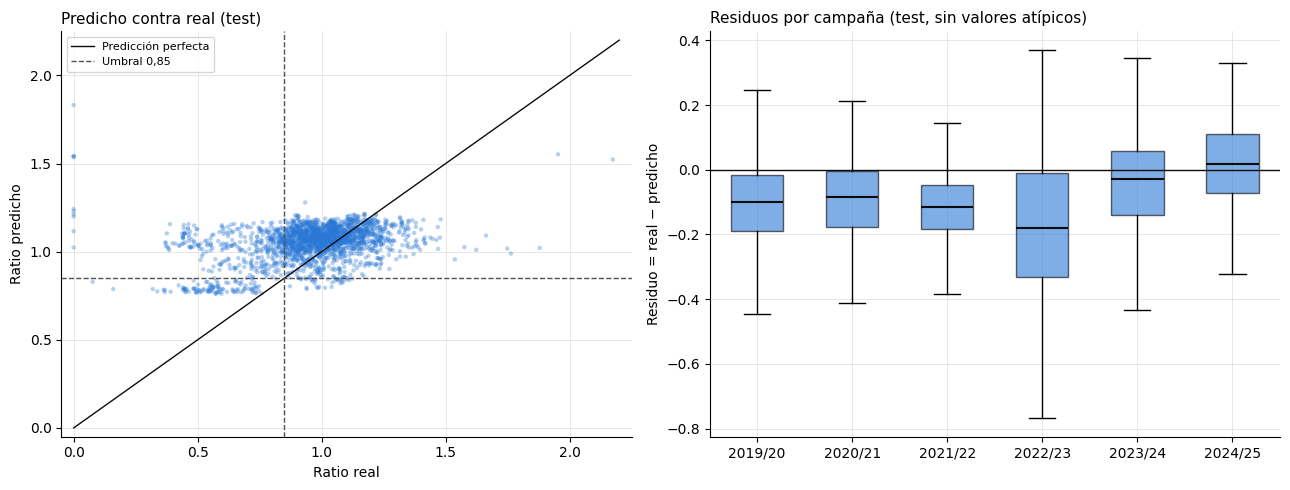

,n,ratio_real,ratio_predicho
ratio,,,
"(-0.01, 0.6]",163,0.466,0.960
"(0.6, 0.75]",138,0.682,0.955
"(0.75, 0.85]",170,0.807,1.027
"(0.85, 0.95]",451,0.904,1.055
"(0.95, 1.05]",556,1.000,1.058
"(1.05, 1.2]",531,1.113,1.075
"(1.2, 3.0]",195,1.299,1.086


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(pred["ratio"], pred["ratio_pred"], s=10, alpha=0.35, color=COLOR_MODELO["KNeighborsRegressor"], edgecolors="none")
ax.plot([0, 2.2], [0, 2.2], color="#0b0b0b", linewidth=1, label="Predicción perfecta")
ax.axvline(THRESHOLD, color=TINTA_SECUNDARIA, linestyle="--", linewidth=1)
ax.axhline(THRESHOLD, color=TINTA_SECUNDARIA, linestyle="--", linewidth=1, label="Umbral 0,85")
ax.set_xlim(-0.05, 2.25)
ax.set_ylim(-0.05, 2.25)
ax.set_xlabel("Ratio real")
ax.set_ylabel("Ratio predicho")
ax.set_title("Predicho contra real (test)", loc="left", fontsize=11)
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
campanias = sorted(pred["campania_inicio"].unique())
datos = [pred.loc[pred["campania_inicio"] == c, "residuo_ratio"] for c in campanias]
caja = ax.boxplot(datos, patch_artist=True, widths=0.55, showfliers=False, medianprops={"color": "#0b0b0b", "linewidth": 1.5})
for parche in caja["boxes"]:
    parche.set_facecolor(COLOR_MODELO["KNeighborsRegressor"])
    parche.set_alpha(0.6)
ax.axhline(0, color="#0b0b0b", linewidth=1)
ax.set_xticks(range(1, len(campanias) + 1), [f"{a}/{str(a + 1)[-2:]}" for a in campanias])
ax.set_ylabel("Residuo = real − predicho")
ax.set_title("Residuos por campaña (test, sin valores atípicos)", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "residuos_regresion.png", dpi=150)
plt.show()

tramos = pd.cut(pred["ratio"], [-0.01, 0.6, 0.75, 0.85, 0.95, 1.05, 1.2, 3])
display(pred.groupby(tramos, observed=True).agg(n=("ratio", "size"), ratio_real=("ratio", "mean"), ratio_predicho=("ratio_pred", "mean")).round(3))

La nube del gráfico izquierdo es mucho más **horizontal** que la diagonal. Es regresión hacia la media: el desvío de la predicción es 0,10 y el del valor real, 0,21. En los casos con ratio real menor a 0,6, el modelo predice en promedio 0,96. Las campañas muy malas y muy buenas quedan subestimadas en su magnitud.

Por campaña, los residuos de 2019/20 a 2021/22 están corridos debajo de 0 (sesgo de nivel), y 2022/23 tiene la caja más baja y más ancha: es la campaña donde más se equivoca, aunque menos que los baselines.

## 7. Errores importantes

Se ordenan por el error en **toneladas del partido**: el error en kg/ha multiplicado por la superficie sembrada. Es la escala en la que el usuario siente el error.

In [15]:
pred["error_t_abs"] = pred["error_t_partido"].abs()
cols = ["cultivo", "campania", "municipio_nombre", "superficie_sembrada", "prev5", "rendimiento",
        "rend_pred_kg", "ratio", "ratio_pred", "error_t_partido"]
display(pred.nlargest(10, "error_t_abs")[cols].round(2).reset_index(drop=True))
print("Pérdidas totales (ratio 0) en test:")
display(pred[pred["ratio"] == 0][["cultivo", "campania", "municipio_nombre", "prev5_ceros", "ratio_pred"]].round(2).reset_index(drop=True))

,cultivo,campania,municipio_nombre,superficie_sembrada,prev5,rendimiento,rend_pred_kg,ratio,ratio_pred,error_t_partido
0,Maíz,2022/23,Carlos Casares,39500.0,8480.0,650.0,7029.05,0.08,0.83,-251972.55
1,Maíz,2021/22,Tres Arroyos,92534.0,6280.0,4000.0,6491.79,0.64,1.03,-230575.20
2,Maíz,2021/22,Necochea,60801.0,6840.0,3500.0,7154.04,0.51,1.05,-222169.48
3,Maíz,2023/24,Coronel Dorrego,91406.0,4820.0,2500.0,4888.15,0.52,1.01,-218291.16
4,Soja total,2022/23,9 De Julio,172000.0,3099.8,1370.0,2468.45,0.44,0.80,-188932.97
5,Trigo total,2022/23,General Villegas,114000.0,3620.0,2000.0,3643.85,0.55,1.01,-187398.91
6,Maíz,2021/22,General Villegas,119000.0,8520.0,7750.0,9290.99,0.91,1.09,-183377.63
7,Trigo total,2022/23,Tres Arroyos,91550.0,4171.6,2433.0,4424.81,0.58,1.06,-182350.18
8,Maíz,2024/25,Trenque Lauquen,135285.0,7740.0,8300.0,6984.58,1.07,0.90,177956.38
9,Maíz,2022/23,9 De Julio,60000.0,8270.0,4000.0,6925.18,0.48,0.84,-175510.84


Pérdidas totales (ratio 0) en test:


,cultivo,campania,municipio_nombre,prev5_ceros,ratio_pred
0,Maíz,2023/24,Bahia Blanca,3,1.54
1,Maíz,2024/25,Bahia Blanca,3,1.54
2,Maíz,2020/21,Dolores,0,1.12
3,Maíz,2021/22,Dolores,1,1.20
4,Maíz,2022/23,Dolores,2,1.21
5,Maíz,2022/23,General Lavalle,0,1.02
6,Maíz,2019/20,Tordillo,2,1.23
7,Maíz,2020/21,Tordillo,2,1.24
8,Maíz,2021/22,Tordillo,3,1.54
9,Maíz,2022/23,Tordillo,4,1.83


- **Nueve de los diez errores más grandes son sobreestimaciones** en campañas malas. El modelo esperaba una campaña normal o apenas baja y el rendimiento cayó fuerte. Son maíz, soja y trigo en partidos grandes del oeste y del sur de la provincia, en 2021/22, 2022/23 y 2023/24. El mayor es maíz 2022/23 en Carlos Casares: se predijeron 7.029 kg/ha y se cosecharon 650 kg/ha, unas 250.000 toneladas de diferencia.
- **El único error grande por subestimación** es maíz 2024/25 en Trenque Lauquen: el modelo esperaba una caída y la campaña fue buena.
- **Las pérdidas totales** (ratio 0) son imposibles de anticipar con estas variables. Son 10 casos, todos de maíz, en partidos donde el cultivo es marginal (Tordillo, Dolores, Bahía Blanca, General Lavalle). El modelo predice ratios normales o altos; con varios ceros previos, `prev5` es bajo y el modelo espera un rebote.

Para el usuario, el error más costoso es el primero: **una campaña mala que el modelo no anticipa**. Es el falso negativo de la alerta, que se analiza en la Clase 4.

## 8. Casos cercanos al umbral

¿Qué pasa si se usa la regresión para generar la alerta, con `ratio predicho < 0,85`?

In [16]:
tramos = pd.cut(pred["ratio"], [-0.01, 0.75, 0.85, 0.95, 10], labels=["< 0,75", "0,75 a 0,85", "0,85 a 0,95", "≥ 0,95"])
cerca = pred.groupby(tramos, observed=True).apply(
    lambda g: pd.Series({
        "n": len(g),
        "clase real": "mala" if g["mala85"].iloc[0] == 1 else "no mala",
        "MAE ratio": g["residuo_ratio"].abs().mean(),
        "% mal clasificado": (g["alerta_regresion"] != g["mala85"]).mean() * 100,
    }),
    include_groups=False,
)
display(cerca.round(3))

alertas = pred["alerta_regresion"]
tp = int(((alertas == 1) & (pred["mala85"] == 1)).sum())
print(f"Alertas emitidas: {int(alertas.sum())} | campañas malas reales: {int(pred['mala85'].sum())} | detectadas: {tp}")

,n,clase real,MAE ratio,% mal clasificado
ratio,,,,
"< 0,75",301,mala,0.393,65.116
"0,75 a 0,85",170,mala,0.220,98.235
"0,85 a 0,95",451,no mala,0.156,1.330
"≥ 0,95",1282,no mala,0.097,2.028


Alertas emitidas: 139 | campañas malas reales: 470 | detectadas: 107


- Las campañas malas **cercanas al umbral** (ratio real entre 0,75 y 0,85) quedan casi todas mal clasificadas: el error en ratio es de solo 0,22, pero alcanza para dejarlas del lado "no mala".
- En las campañas **muy malas** (ratio real menor a 0,75), el modelo detecta alrededor de un tercio.
- En las campañas normales casi no hay falsas alarmas.

Esto responde una de las preguntas del informe: **sí, se puede tener un MAE aceptable y una clasificación mala**. La regresión hacia la media empuja las predicciones hacia 1 y lejos del umbral. La alerta por regresión detecta el 23% de las campañas malas, frente al 0% de los baselines, con una precisión del 77%. El clasificador directo de la Clase 4 tiene que mejorar ese recall.

## 9. Regresor seleccionado

El regresor final es **KNN con clima, k = 300 y pesos por distancia**, reentrenado con train + validación. Se guarda como Pipeline completo, con el preprocesamiento incluido, en `modelos/regresor.joblib`, junto con su metadata.

Se selecciona por su desempeño en validación, siguiendo el protocolo. En test supera al Dummy en todas las métricas y al promedio de 5 campañas en RMSE, R² en kg/ha, la campaña 2022/23, soja y detección de campañas malas. No lo supera en MAE global.

In [17]:
modelo = joblib.load(REGRESOR_FILE)
print(modelo)
print(REGRESOR_METADATA.read_text(encoding="utf-8"))

ejemplo = test[(test["municipio_nombre"] == "Chascomus") & (test["campania_inicio"] == 2022)]
if ejemplo.empty:
    ejemplo = test[test["campania_inicio"] == 2022].head(4)
entrada = ejemplo[list(modelo.feature_names_in_)]
ratio_pred = modelo.predict(entrada)
display(ejemplo[["cultivo", "campania", "municipio_nombre", "prev5", "rendimiento", "ratio"]].assign(
    ratio_predicho=ratio_pred.round(3),
    rendimiento_predicho_kg=(ratio_pred * ejemplo["prev5"]).round(0),
    alerta_regresion=np.where(ratio_pred < THRESHOLD, "sí", "no"),
))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cultivo',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['cultivo']),
                                                 ('superficie',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('escala',
                                                                   StandardScaler())]),
                                                  ['superficie_sembrada']),
                                                 ('numericas', Sta

,cultivo,campania,municipio_nombre,prev5,rendimiento,ratio,ratio_predicho,rendimiento_predicho_kg,alerta_regresion
1055,Girasol,2022/23,Chascomus,2340.0,2200.0,0.940171,0.950,2223.0,no
4856,Maíz,2022/23,Chascomus,7810.0,5506.0,0.704994,0.789,6160.0,sí
8801,Soja total,2022/23,Chascomus,2935.8,1424.0,0.485047,0.792,2325.0,sí
12315,Trigo total,2022/23,Chascomus,4080.0,2191.0,0.537010,1.062,4333.0,no


## 10. Conclusiones

1. **¿Supera al baseline?** Supera al Dummy en validación y en test. Contra el promedio de 5 campañas, gana en validación y pierde en el MAE de test (0,159 contra 0,154). Gana en RMSE y R² en kg/ha, en soja y en la sequía 2022/23.
2. **¿Qué significa el MAE?** Un MAE de 0,159 en ratio equivale a 637 kg/ha: en promedio, la predicción se aleja del rendimiento real alrededor de un 16% del promedio histórico del partido. Para maíz, el cultivo de mayor rendimiento, el error ronda los 1.000 kg/ha.
3. **Profundidad y k.** El árbol sobreajusta desde profundidad 8; el óptimo es 4. KNN necesita muchos vecinos (k = 300) porque la señal es ruidosa.
4. **El clima aporta, pero no en todos los cultivos.** La precipitación de la ventana es la variable más importante. Hay señal clara en soja y maíz y casi nula en trigo y girasol.
5. **El problema principal es el sesgo de nivel.** El test es más malo que cualquier período de entrenamiento. Sin el sesgo, el modelo superaría al baseline, pero ese ajuste no está disponible al predecir.
6. **Buen MAE no implica buena alerta.** Por la regresión hacia la media, la alerta por regresión detecta solo el 23% de las campañas malas y casi ninguna de las cercanas al umbral.
7. **Para la Clase 4:** un clasificador directo puede aprender la frontera sin pasar por la regresión y tener mejor recall. También conviene evaluar con validación un modelo por cultivo y alguna forma de recalibrar el nivel que no use el test.

## 11. Reproducibilidad

```bash
python -m src.regresion
python -m nbconvert --to notebook --execute --inplace notebooks/03_regresion.ipynb
```